# PaperLu1 — Cohort-by-cohort ANOVA discovery and one-versus-rest transportability of circulating miRNA signatures for lung cancer

**Design.** Each of the seven blood cohorts is used *independently* as a discovery cohort. Within it, a one-way ANOVA
(two groups: lung cancer vs. healthy control) ranks miRNAs; the top-*k* miRNAs train a classifier which is then applied,
unchanged, to every other cohort ("one versus the rest"). A complementary leave-one-cohort-out (LOCO) analysis trains on
the pooled remaining cohorts and tests on the held-out one.

**Key data-integrity steps** (see Section 2): (i) harmonisation of miRBase v13 names (febit/GPL9040) to MIMAT accessions;
(ii) a cross-series sample-overlap audit, because several GEO series from the same biobank re-deposit identical arrays;
(iii) a sensitivity analysis removing the sample-level global intensity component (row-centering).

Outputs: `figures/` (PNG 300 dpi + PDF) and `tables/` (CSV + one XLSX workbook), `results_summary.json`.

In [1]:
import os, sys, json, time, warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from functools import reduce
from scipy import stats
sys.path.insert(0, os.path.abspath(".."))
sys.path.insert(0, os.path.abspath("."))
from lung_mirna_utils import *
from sklearn.model_selection import StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.base import clone

set_plot_style()
FIG = "figures"; TAB = "tables"
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)
RS = 42
K_MAIN = 10
K_GRID = [5, 10, 20, 50]
MODELS = ["LR", "SVM", "RF", "XGB"]
RESULTS = {}
t0 = time.time()

def savefig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)

## 1. Data loading and harmonisation

In [2]:
alias = load_alias_table()
NAMES = mimat_names(alias)
data = {}
map_reports = {}
for c in COHORT_ORDER:
    X, y, rep = load_cohort(c, alias=alias, return_report=True)
    data[c] = (X, y)
    if rep is not None:
        map_reports[c] = rep
U = sorted(reduce(lambda a, b: a & b, [set(X.columns) for X, _ in data.values()]))
print("Common MIMAT universe across 7 cohorts:", len(U))
for c, rep in map_reports.items():
    rep.to_csv(f"{TAB}/S1_{c}_legacy_name_mapping_issues.csv", index=False)

rows = []
for c in COHORT_ORDER:
    X, y = data[c]; info = COHORTS[c]
    rows.append(dict(Cohort=c, Specimen=info["specimen"], Platform=info["platform"], Origin=info["country"],
                     Family=info["family"], N=len(y), Cases=int(y.sum()), Controls=int((y == 0).sum()),
                     Prevalence=round(y.mean(), 3), miRNAs_deposited=X.shape[1], miRNAs_in_common_universe=len(U)))
T1 = pd.DataFrame(rows)
T1.to_csv(f"{TAB}/Table1_cohort_characteristics.csv", index=False)
T1

Common MIMAT universe across 7 cohorts: 816


,Cohort,Specimen,Platform,Origin,Family,N,Cases,Controls,Prevalence,miRNAs_deposited,miRNAs_in_common_universe
0,E-MTAB-8026,Whole blood (PAXgene),Agilent SurePrint miRNA microarray,Germany (multicentre),WB-Agilent,1570,606,964,0.386,2549,816
1,GSE137140,Serum,Toray 3D-Gene Human miRNA V21 (GPL21263),Japan (NCC Biobank),Serum-3DGene,3744,1566,2178,0.418,2565,816
2,GSE106817,Serum,Toray 3D-Gene Human miRNA V21 (GPL21263),Japan (NCC Biobank),Serum-3DGene,2874,115,2759,0.040,2565,816
3,GSE112264,Serum,Toray 3D-Gene Human miRNA V21 (GPL21263),Japan (NCC Biobank),Serum-3DGene,91,50,41,0.549,2565,816
4,GSE113486,Serum,Toray 3D-Gene Human miRNA V21 (GPL21263),Japan (NCC Biobank),Serum-3DGene,140,40,100,0.286,2565,816
5,GSE31568,Whole blood (PAXgene),febit Geniom Biochip miRBase v13 (GPL9040),Germany,WB-Geniom,102,32,70,0.314,861,816
6,GSE61741,Whole blood (PAXgene),febit Geniom Biochip miRBase v13 (GPL9040),Germany,WB-Geniom,167,73,94,0.437,846,816


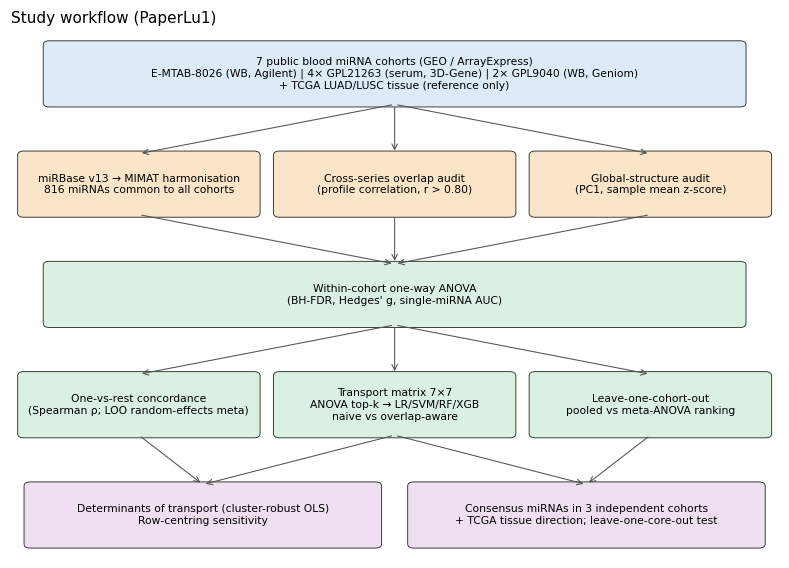

In [3]:
fig, ax = plt.subplots(figsize=(9, 6.2))
B, O, G, P = "#DCEBF7", "#FBE5C8", "#D9F0E3", "#EEE0F0"
draw_flow(ax, [
    [("7 public blood miRNA cohorts (GEO / ArrayExpress)\nE-MTAB-8026 (WB, Agilent) | 4× GPL21263 (serum, 3D-Gene) | 2× GPL9040 (WB, Geniom)\n+ TCGA LUAD/LUSC tissue (reference only)", B)],
    [("miRBase v13 → MIMAT harmonisation\n816 miRNAs common to all cohorts", O), ("Cross-series overlap audit\n(profile correlation, r > 0.80)", O), ("Global-structure audit\n(PC1, sample mean z-score)", O)],
    [("Within-cohort one-way ANOVA\n(BH-FDR, Hedges' g, single-miRNA AUC)", G)],
    [("One-vs-rest concordance\n(Spearman ρ; LOO random-effects meta)", G), ("Transport matrix 7×7\nANOVA top-k → LR/SVM/RF/XGB\nnaive vs overlap-aware", G), ("Leave-one-cohort-out\npooled vs meta-ANOVA ranking", G)],
    [("Determinants of transport (cluster-robust OLS)\nRow-centring sensitivity", P), ("Consensus miRNAs in 3 independent cohorts\n+ TCGA tissue direction; leave-one-core-out test", P)],
], title="Study workflow (PaperLu1)")
savefig(fig, "Fig1_study_design")

## 2. Cross-series sample-overlap audit
Profiles are compared by Pearson correlation across shared miRNAs. Within-cohort nearest-neighbour correlations are ~0.3–0.5,
whereas re-deposited arrays correlate at r > 0.89; the distribution is bimodal with an empty 0.80–0.85 gap, so r > 0.80 is used.

In [4]:
pair_tab, clusters = overlap_audit(data)
pair_tab.to_csv(f"{TAB}/Table2_overlap_audit_pairs.csv", index=False)
clusters.to_csv(f"{TAB}/S2_sample_overlap_clusters.csv", index=False)
T2 = pair_tab[pair_tab.dup_a > 0].copy()
print(T2[["cohort_a", "cohort_b", "n_a", "n_b", "dup_a", "dup_cases", "dup_controls", "label_concordance", "min_r_dup"]])
uniq = clusters.groupby("cohort").apply(lambda d: pd.Series(dict(
    N=len(d), in_other_series=int((d.n_series > 1).sum()),
    unique_cases=int(((d.n_series == 1) & (d.label == 1)).sum()),
    unique_controls=int(((d.n_series == 1) & (d.label == 0)).sum())))).reindex(COHORT_ORDER)
uniq.to_csv(f"{TAB}/Table2b_unique_samples_per_cohort.csv")
RESULTS["overlap"] = {"pairs": T2.to_dict(orient="records"), "unique": uniq.reset_index().to_dict(orient="records"),
                      "n_clusters_total": int(clusters.cluster.nunique()), "n_profiles_total": int(len(clusters))}
uniq

     cohort_a   cohort_b   n_a   n_b  dup_a  dup_cases  dup_controls  \
6   GSE137140  GSE106817  3744  2874   1149        111          1038   
7   GSE137140  GSE112264  3744    91     65         47            18   
8   GSE137140  GSE113486  3744   140     86         36            50   
12  GSE106817  GSE113486  2874   140     46          2            44   
15  GSE112264  GSE113486    91   140      1          1             0   
20   GSE31568   GSE61741   102   167     82         31            51   

    label_concordance  min_r_dup  
6                 1.0   0.890225  
7                 1.0   0.969221  
8                 1.0   0.958200  
12                1.0   0.968929  
15                1.0   0.967924  
20                1.0   0.938077  


,N,in_other_series,unique_cases,unique_controls
cohort,,,,
E-MTAB-8026,1570,0,606,964
GSE137140,3744,1272,1374,1098
GSE106817,2874,1168,3,1703
GSE112264,91,65,3,23
GSE113486,140,105,3,32
GSE31568,102,82,1,19
GSE61741,167,82,42,43


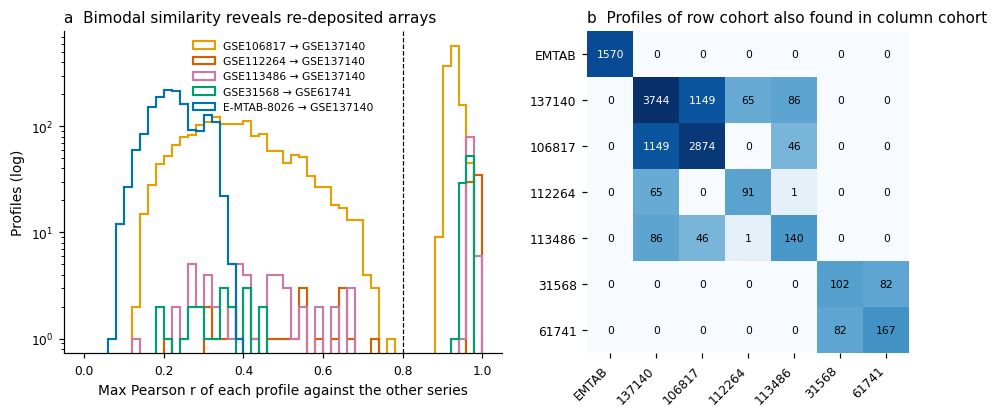

In [5]:
from lung_mirna_utils import _rowz
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axes[0]
show = [("GSE106817", "GSE137140"), ("GSE112264", "GSE137140"), ("GSE113486", "GSE137140"), ("GSE31568", "GSE61741"),
        ("E-MTAB-8026", "GSE137140")]
cols = ["#E69F00", "#D55E00", "#CC79A7", "#009E73", "#0072B2"]
for (a, b), col in zip(show, cols):
    Xa, _ = data[a]; Xb, _ = data[b]
    f = sorted(set(Xa.columns) & set(Xb.columns))
    mx = (_rowz(Xa[f].values) @ _rowz(Xb[f].values).T).max(1)
    ax.hist(mx, bins=np.linspace(0, 1, 51), histtype="step", lw=1.4, color=col, label=f"{a} → {b}")
ax.axvline(0.80, ls="--", c="k", lw=0.8); ax.set_yscale("log")
ax.set_xlabel("Max Pearson r of each profile against the other series"); ax.set_ylabel("Profiles (log)")
ax.set_title("a  Bimodal similarity reveals re-deposited arrays", loc="left"); ax.legend(frameon=False, fontsize=7)
ax = axes[1]
M = pd.DataFrame(0, index=COHORT_ORDER, columns=COHORT_ORDER)
for c in COHORT_ORDER:
    M.loc[c, c] = len(data[c][1])
for a, b in itertools.permutations(COHORT_ORDER, 2):
    M.loc[a, b] = len(overlap_ids(clusters, a, [b]))
im = ax.imshow(np.log10(M.values + 1), cmap="Blues")
for i in range(7):
    for j in range(7):
        v = M.values[i, j]
        ax.text(j, i, f"{v}", ha="center", va="center", fontsize=7, color="white" if np.log10(v + 1) > 2.3 else "black")
ax.set_xticks(range(7)); ax.set_yticks(range(7))
ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER], rotation=45, ha="right"); ax.set_yticklabels([SHORT[c] for c in COHORT_ORDER])
ax.set_title("b  Profiles of row cohort also found in column cohort", loc="left")
ax.spines[:].set_visible(False)
savefig(fig, "Fig2_overlap_audit")

## 3. Global structure of the expression matrices (pre-analytical signal)
The deposited matrices are per-cohort z-scores. We quantify (i) variance explained by PC1 and (ii) how well PC1 and the
per-sample mean z-score (a proxy for global circulating-miRNA intensity / technical drift) separate cases from controls.

In [6]:
gs_rows = []
for c in COHORT_ORDER:
    X, y = data[c]
    p = PCA(10, random_state=RS).fit(X.values); Z = p.transform(X.values)
    a1 = roc_auc_score(y, Z[:, 0]); rm = X.mean(axis=1).values; a2 = roc_auc_score(y, rm)
    gs_rows.append(dict(Cohort=c, PC1_var=p.explained_variance_ratio_[0], PC2_var=p.explained_variance_ratio_[1],
                        PC1_AUC=max(a1, 1 - a1), RowMean_AUC=max(a2, 1 - a2),
                        RowMean_direction="higher in cancer" if a2 > 0.5 else "lower in cancer"))
GS = pd.DataFrame(gs_rows); GS.to_csv(f"{TAB}/Table3_global_structure.csv", index=False)
RESULTS["global_structure"] = GS.to_dict(orient="records")
GS

,Cohort,PC1_var,PC2_var,PC1_AUC,RowMean_AUC,RowMean_direction
0,E-MTAB-8026,0.691935,0.178046,0.611605,0.604768,higher in cancer
1,GSE137140,0.296450,0.046803,0.953833,0.931181,higher in cancer
2,GSE106817,0.199660,0.093448,0.959087,0.925912,higher in cancer
3,GSE112264,0.331945,0.056001,0.999512,0.980000,higher in cancer
4,GSE113486,0.243284,0.077644,0.984250,0.922500,higher in cancer
5,GSE31568,0.147198,0.072045,0.588393,0.510714,higher in cancer
6,GSE61741,0.116710,0.058315,0.686972,0.547945,lower in cancer


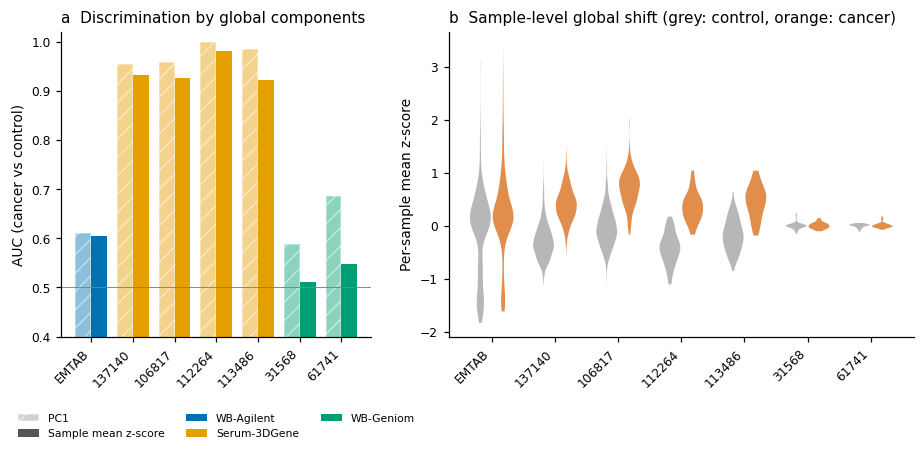

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1, 1.5]))
ax = axes[0]
xx = np.arange(7); w = 0.38
fam_col = [FAMILY_COLORS[COHORTS[c]["family"]] for c in COHORT_ORDER]
ax.bar(xx - w / 2, GS.PC1_AUC, w, color=fam_col, alpha=0.45, hatch="//", edgecolor="white")
ax.bar(xx + w / 2, GS.RowMean_AUC, w, color=fam_col)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(fc="#999999", alpha=0.45, hatch="//", ec="white", label="PC1"),
                   Patch(fc="#555555", label="Sample mean z-score")] +
          [Patch(fc=v, label=k) for k, v in FAMILY_COLORS.items()], frameon=False, fontsize=7, loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=3)
ax.axhline(0.5, c="grey", lw=0.6)
ax.set_xticks(xx); ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER], rotation=45, ha="right")
ax.set_ylim(0.4, 1.02); ax.set_ylabel("AUC (cancer vs control)")
ax.set_title("a  Discrimination by global components", loc="left")
ax = axes[1]
pos = 0; ticks = []
for c in COHORT_ORDER:
    X, y = data[c]; rm = X.mean(axis=1).values
    for lab, off, col in [(0, -0.18, "#999999"), (1, 0.18, "#D55E00")]:
        v = rm[y == lab]
        parts = ax.violinplot(v, positions=[pos + off], widths=0.33, showextrema=False)
        for b in parts["bodies"]:
            b.set_facecolor(col); b.set_alpha(0.7)
    ticks.append(pos); pos += 1
ax.set_xticks(ticks); ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER], rotation=45, ha="right")
ax.set_ylabel("Per-sample mean z-score"); ax.set_title("b  Sample-level global shift (grey: control, orange: cancer)", loc="left")
savefig(fig, "Fig3_global_structure")

## 4. Within-cohort ANOVA (each cohort independently)

In [8]:
anova = {}
anova_full = {}
for c in COHORT_ORDER:
    X, y = data[c]
    anova[c] = anova_table(X[U], y)                     # common universe (used for transport)
    anova_full[c] = anova_table(X, y)                   # all deposited miRNAs
    at = anova_full[c].copy(); at.insert(1, "miRNA", at.feature.map(NAMES))
    at.to_csv(f"{TAB}/S3_ANOVA_full_{c}.csv", index=False)
sum_rows = []
for c in COHORT_ORDER:
    af, au = anova_full[c], anova[c]
    top = au.head(10)
    sum_rows.append(dict(Cohort=c, Tested=len(af), FDR005=int((af.FDR < 0.05).sum()),
                         FDR005_pct=round(100 * (af.FDR < 0.05).mean(), 1),
                         Bonf005=int((af.p < 0.05 / len(af)).sum()),
                         Tested_common=len(au), FDR005_common=int((au.FDR < 0.05).sum()),
                         max_abs_g=round(au.hedges_g.abs().max(), 2),
                         max_single_AUC=round(np.maximum(au.AUC, 1 - au.AUC).max(), 3),
                         Top5_common="; ".join(NAMES.get(f, f) for f in top.feature[:5])))
T4 = pd.DataFrame(sum_rows); T4.to_csv(f"{TAB}/Table4_within_cohort_ANOVA_summary.csv", index=False)
RESULTS["anova_summary"] = T4.to_dict(orient="records")
T4

,Cohort,Tested,FDR005,FDR005_pct,Bonf005,Tested_common,FDR005_common,max_abs_g,max_single_AUC,Top5_common
0,E-MTAB-8026,2549,2427,95.2,2198,816,714,0.71,0.713,hsa-miR-940; hsa-miR-33b-3p; hsa-miR-1290; hsa...
1,GSE137140,2565,2480,96.7,2380,816,798,3.86,0.998,hsa-miR-1228-5p; hsa-miR-663a; hsa-miR-1268a; ...
2,GSE106817,2565,2327,90.7,2040,816,770,4.25,0.996,hsa-miR-1228-5p; hsa-miR-1469; hsa-miR-663a; h...
3,GSE112264,2565,2082,81.2,1529,816,722,6.02,1.000,hsa-miR-1228-5p; hsa-miR-614; hsa-miR-1290; hs...
4,GSE113486,2565,2040,79.5,1367,816,693,5.05,0.997,hsa-miR-1228-5p; hsa-miR-663a; hsa-miR-1469; h...
5,GSE31568,861,29,3.4,5,816,27,1.20,0.812,hsa-miR-199a-5p; hsa-miR-647; hsa-miR-624-5p; ...
6,GSE61741,846,328,38.8,96,816,315,1.42,0.835,hsa-miR-107; hsa-miR-17-5p; hsa-miR-144-5p; hs...


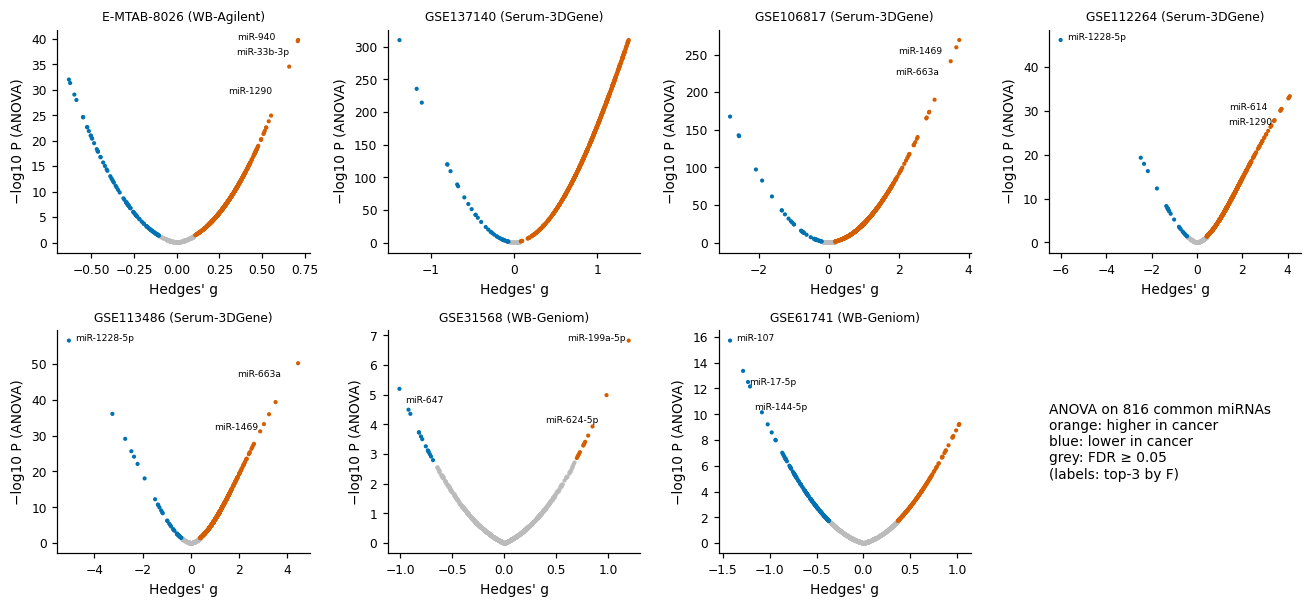

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6)); axes = axes.ravel()
for ax, c in zip(axes, COHORT_ORDER):
    au = anova[c]
    lp = au.neglog10p
    sig = au.FDR < 0.05
    ax.scatter(au.hedges_g[~sig], lp[~sig], s=3, c="#BBBBBB", rasterized=True)
    ax.scatter(au.hedges_g[sig], lp[sig], s=3, c=np.where(au.hedges_g[sig] > 0, "#D55E00", "#0072B2"), rasterized=True)
    for n_, (_, r) in enumerate(au.head(3).iterrows()):
        ax.annotate(NAMES.get(r.feature, r.feature).replace("hsa-", ""), (r.hedges_g, r.neglog10p),
                    fontsize=6, xytext=(-40 if r.hedges_g > 0 else 4, -9 * n_), textcoords="offset points")
    ax.set_title(f"{c} ({COHORTS[c]['family']})", fontsize=8)
    ax.set_xlabel("Hedges' g"); ax.set_ylabel("−log10 P (ANOVA)")
axes[-1].axis("off")
axes[-1].text(0, 0.5, f"ANOVA on {len(U)} common miRNAs\norange: higher in cancer\nblue: lower in cancer\ngrey: FDR ≥ 0.05\n(labels: top-3 by F)",
              fontsize=9, va="center")
fig.tight_layout()
savefig(fig, "Fig4_volcano_per_cohort")

## 5. One-versus-rest concordance of ANOVA effect sizes
(a) Pairwise Spearman correlation of Hedges' g across the common universe.
(b) Each cohort vs. a leave-one-out DerSimonian–Laird random-effects meta-analysis of the *other* cohorts, after removing
samples that overlap with the held-out cohort and de-duplicating the remaining pool.

In [10]:
G = pd.DataFrame({c: anova[c].set_index("feature").loc[U, "hedges_g"] for c in COHORT_ORDER})
R = G.corr(method="spearman")
R.to_csv(f"{TAB}/S4_pairwise_spearman_hedges_g.csv")

def dedup_pool(test_cohort, pool_cohorts):
    """Return {cohort: boolean mask} keeping samples not overlapping with test and first copy across pool."""
    bad = set(clusters.loc[clusters.cohort == test_cohort, "cluster"]) if test_cohort else set()
    seen = set(); masks = {}
    order = sorted(pool_cohorts, key=lambda c: -len(data[c][1]))  # keep copy in the larger series
    for c in order:
        cl = clusters[clusters.cohort == c].set_index("sample_id").loc[data[c][0].index, "cluster"].values
        m = np.array([(k not in bad) and (k not in seen) for k in cl])
        seen.update(cl[m]); masks[c] = m
    return masks

ovr_rows = []
meta_store = {}
for c in COHORT_ORDER:
    rest = [r for r in COHORT_ORDER if r != c]
    masks = dedup_pool(c, rest)
    gs, vs, used = [], [], []
    for r in rest:
        X, y = data[r]; m = masks[r]
        if (y[m] == 1).sum() < 5 or (y[m] == 0).sum() < 5:
            continue
        at = anova_table(X.loc[m, U], y[m]).set_index("feature").loc[U]
        n1, n0 = (y[m] == 1).sum(), (y[m] == 0).sum()
        gs.append(at.hedges_g.values); vs.append(hedges_g_var(at.hedges_g.values, n1, n0)); used.append(r)
    meta = dl_meta(np.column_stack(gs), np.column_stack(vs)); meta.index = U
    meta_store[c] = meta
    g_self = G[c]
    rho = stats.spearmanr(g_self, meta.g_meta).correlation
    top_self = anova[c].feature[:50]; top_rest = meta.z.abs().sort_values(ascending=False).index[:50]
    sign_top = np.mean(np.sign(g_self[top_self]) == np.sign(meta.g_meta[top_self]))
    ovr_rows.append(dict(Cohort=c, Rest_cohorts_used=", ".join(used), Spearman_vs_rest=rho,
                         Top50_overlap=len(set(top_self) & set(top_rest)), Top50_Jaccard=jaccard(top_self, top_rest),
                         Sign_agreement_top50=sign_top,
                         Median_I2=float(meta.I2.median())))
OVR = pd.DataFrame(ovr_rows); OVR.to_csv(f"{TAB}/Table5_one_vs_rest_concordance.csv", index=False)
RESULTS["one_vs_rest"] = OVR.to_dict(orient="records")
OVR

,Cohort,Rest_cohorts_used,Spearman_vs_rest,Top50_overlap,Top50_Jaccard,Sign_agreement_top50,Median_I2
0,E-MTAB-8026,"GSE137140, GSE61741",-0.015378,1,0.010101,0.62,0.972520
1,GSE137140,"E-MTAB-8026, GSE61741",-0.089680,8,0.086957,0.66,0.789421
2,GSE106817,"E-MTAB-8026, GSE137140, GSE61741",0.541873,0,0.000000,0.96,0.987114
3,GSE112264,"E-MTAB-8026, GSE137140, GSE61741",0.528036,0,0.000000,1.00,0.988674
4,GSE113486,"E-MTAB-8026, GSE137140, GSE61741",0.566663,1,0.010101,1.00,0.988714
5,GSE31568,"E-MTAB-8026, GSE137140, GSE61741",0.000494,3,0.030928,0.46,0.987951
6,GSE61741,"E-MTAB-8026, GSE137140",-0.098951,1,0.010101,0.46,0.993185


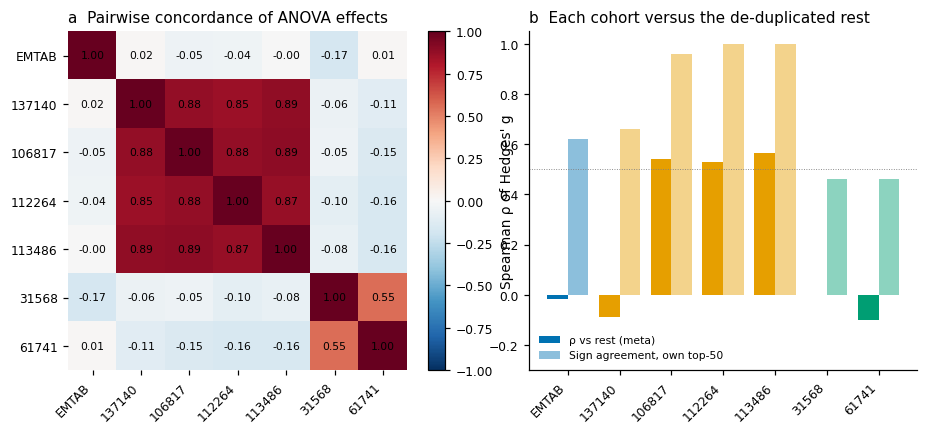

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = axes[0]
im = ax.imshow(R.values, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{R.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xticks(range(7)); ax.set_yticks(range(7))
ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER], rotation=45, ha="right"); ax.set_yticklabels([SHORT[c] for c in COHORT_ORDER])
plt.colorbar(im, ax=ax, fraction=0.046, label="Spearman ρ of Hedges' g")
ax.set_title("a  Pairwise concordance of ANOVA effects", loc="left"); ax.spines[:].set_visible(False)
ax = axes[1]
xx = np.arange(7)
ax.bar(xx - 0.2, OVR.Spearman_vs_rest, 0.4, color=fam_col, label="ρ vs rest (meta)")
ax.bar(xx + 0.2, OVR.Sign_agreement_top50, 0.4, color=fam_col, alpha=0.45, label="Sign agreement, own top-50")
ax.axhline(0.5, c="grey", lw=0.6, ls=":")
ax.set_xticks(xx); ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER], rotation=45, ha="right")
ax.set_ylim(-0.3, 1.05); ax.legend(frameon=False, fontsize=7)
ax.set_title("b  Each cohort versus the de-duplicated rest", loc="left")
savefig(fig, "Fig5_concordance")

## 6. Transport matrix: ANOVA top-k in cohort *i* → classifier → every cohort *j*
Diagonal = nested 5-fold CV (ANOVA re-run inside each training fold). Off-diagonal = locked model applied to cohort *j*;
**naive** uses all samples of *j*, **overlap-aware** removes samples of *j* that also appear in *i*.

In [12]:
def fit_predict(Xtr, ytr, Xte, model_name, feats):
    spw = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
    m = clone(make_models(RS, spw)[model_name])
    m.fit(Xtr[feats].values, ytr)
    return score_of(m, Xte[feats].values), m

def nested_cv_auc(X, y, k, model_name, n_splits=5, seed=RS):
    skf = StratifiedKFold(n_splits=min(n_splits, int(min(y.sum(), (y == 0).sum()))), shuffle=True, random_state=seed)
    s = np.zeros(len(y))
    for tr, te in skf.split(X, y):
        feats = anova_table(X.iloc[tr], y[tr]).feature[:k].tolist()
        s[te], _ = fit_predict(X.iloc[tr], y[tr], X.iloc[te], model_name, feats)
    return roc_auc_score(y, s)

def rowcenter(X):
    return restandardize(X.sub(X.mean(axis=1), axis=0))

def transport(variant="as_deposited", ks=K_GRID, models=MODELS):
    recs = []
    D = {c: ((rowcenter(data[c][0][U]) if variant == "row_centered" else data[c][0][U]), data[c][1]) for c in COHORT_ORDER}
    for i in COHORT_ORDER:
        Xi, yi = D[i]
        rank_i = anova_table(Xi, yi).feature.tolist()
        for k in ks:
            feats = rank_i[:k]
            for mn in models:
                spw = (yi == 0).sum() / max(yi.sum(), 1)
                m = clone(make_models(RS, spw)[mn]).fit(Xi[feats].values, yi)
                for j in COHORT_ORDER:
                    Xj, yj = D[j]
                    if i == j:
                        if k == K_MAIN or mn == "LR":
                            a = nested_cv_auc(Xi, yi, k, mn)
                            recs.append(dict(variant=variant, train=i, test=j, k=k, model=mn, setting="internal_nestedCV",
                                             n_test=len(yj), cases_test=int(yj.sum()), AUC=a, AUC_lo=np.nan, AUC_hi=np.nan))
                        continue
                    s = score_of(m, Xj[feats].values)
                    a, lo, hi = auc_delong(yj, s)
                    recs.append(dict(variant=variant, train=i, test=j, k=k, model=mn, setting="naive",
                                     n_test=len(yj), cases_test=int(yj.sum()), AUC=a, AUC_lo=lo, AUC_hi=hi))
                    ov = overlap_ids(clusters, j, [i])
                    keep = ~Xj.index.isin(list(ov))
                    if keep.sum() and (yj[keep] == 1).sum() >= 3 and (yj[keep] == 0).sum() >= 3:
                        a2, lo2, hi2 = auc_delong(yj[keep], s[keep])
                    else:
                        a2 = lo2 = hi2 = np.nan
                    recs.append(dict(variant=variant, train=i, test=j, k=k, model=mn, setting="overlap_aware",
                                     n_test=int(keep.sum()), cases_test=int(yj[keep].sum()), AUC=a2, AUC_lo=lo2, AUC_hi=hi2))
        print(variant, i, "done", round(time.time() - t0), "s")
    return pd.DataFrame(recs)

TR = transport("as_deposited")
TR.to_csv(f"{TAB}/S5_transport_all_k_models.csv", index=False)

as_deposited E-MTAB-8026 done 77 s
as_deposited GSE137140 done 144 s
as_deposited GSE106817 done 201 s
as_deposited GSE112264 done 218 s
as_deposited GSE113486 done 234 s
as_deposited GSE31568 done 251 s
as_deposited GSE61741 done 272 s


In [13]:
def mat(df, setting, k=K_MAIN, model="LR"):
    d = df[(df.k == k) & (df.model == model) & (df.setting.isin([setting, "internal_nestedCV"]))]
    return d.pivot_table(index="train", columns="test", values="AUC").reindex(index=COHORT_ORDER, columns=COHORT_ORDER)

M_naive, M_aware = mat(TR, "naive"), mat(TR, "overlap_aware")
N_aware = TR[(TR.k == K_MAIN) & (TR.model == "LR") & (TR.setting == "overlap_aware")].pivot_table(
    index="train", columns="test", values="n_test").reindex(index=COHORT_ORDER, columns=COHORT_ORDER)
C_aware = TR[(TR.k == K_MAIN) & (TR.model == "LR") & (TR.setting == "overlap_aware")].pivot_table(
    index="train", columns="test", values="cases_test").reindex(index=COHORT_ORDER, columns=COHORT_ORDER)
T6 = M_aware.round(3).astype(str)
for i in COHORT_ORDER:
    for j in COHORT_ORDER:
        if i != j:
            T6.loc[i, j] = (f"{M_aware.loc[i, j]:.3f} (naive {M_naive.loc[i, j]:.3f}; n={int(N_aware.loc[i, j])}, "
                            f"cases={int(C_aware.loc[i, j])})" if np.isfinite(M_aware.loc[i, j]) else
                            f"NE (naive {M_naive.loc[i, j]:.3f}; cases={int(C_aware.loc[i, j])})")
        else:
            T6.loc[i, j] = f"{M_aware.loc[i, j]:.3f} (nested CV)"
T6.to_csv(f"{TAB}/Table6_transport_matrix_LR_k10.csv")
RESULTS["transport_LR_k10_aware"] = M_aware.round(4).to_dict()
RESULTS["transport_LR_k10_naive"] = M_naive.round(4).to_dict()
T6

test,E-MTAB-8026,GSE137140,GSE106817,GSE112264,GSE113486,GSE31568,GSE61741
train,,,,,,,
E-MTAB-8026,0.850 (nested CV),"0.642 (naive 0.642; n=3744, cases=1566)","0.660 (naive 0.660; n=2874, cases=115)","0.649 (naive 0.649; n=91, cases=50)","0.685 (naive 0.685; n=140, cases=40)","0.497 (naive 0.497; n=102, cases=32)","0.559 (naive 0.559; n=167, cases=73)"
GSE137140,"0.460 (naive 0.460; n=1570, cases=606)",0.994 (nested CV),"0.994 (naive 0.995; n=1725, cases=4)","0.986 (naive 0.990; n=26, cases=3)","1.000 (naive 1.000; n=54, cases=4)","0.416 (naive 0.416; n=102, cases=32)","0.487 (naive 0.487; n=167, cases=73)"
GSE106817,"0.511 (naive 0.511; n=1570, cases=606)","0.970 (naive 0.980; n=2595, cases=1455)",0.999 (nested CV),"0.997 (naive 0.997; n=91, cases=50)","0.996 (naive 0.998; n=94, cases=38)","0.385 (naive 0.385; n=102, cases=32)","0.483 (naive 0.483; n=167, cases=73)"
GSE112264,"0.601 (naive 0.601; n=1570, cases=606)","0.987 (naive 0.987; n=3679, cases=1519)","0.998 (naive 0.998; n=2874, cases=115)",1.000 (nested CV),"0.999 (naive 0.999; n=139, cases=39)","0.577 (naive 0.577; n=102, cases=32)","0.671 (naive 0.671; n=167, cases=73)"
GSE113486,"0.561 (naive 0.561; n=1570, cases=606)","0.982 (naive 0.982; n=3658, cases=1530)","0.994 (naive 0.994; n=2828, cases=113)","1.000 (naive 1.000; n=90, cases=49)",0.999 (nested CV),"0.460 (naive 0.460; n=102, cases=32)","0.384 (naive 0.384; n=167, cases=73)"
GSE31568,"0.404 (naive 0.404; n=1570, cases=606)","0.391 (naive 0.391; n=3744, cases=1566)","0.427 (naive 0.427; n=2874, cases=115)","0.396 (naive 0.396; n=91, cases=50)","0.450 (naive 0.450; n=140, cases=40)",0.787 (nested CV),"0.645 (naive 0.807; n=85, cases=42)"
GSE61741,"0.656 (naive 0.656; n=1570, cases=606)","0.103 (naive 0.103; n=3744, cases=1566)","0.034 (naive 0.034; n=2874, cases=115)","0.036 (naive 0.036; n=91, cases=50)","0.066 (naive 0.066; n=140, cases=40)",NE (naive 0.728; cases=1),0.865 (nested CV)


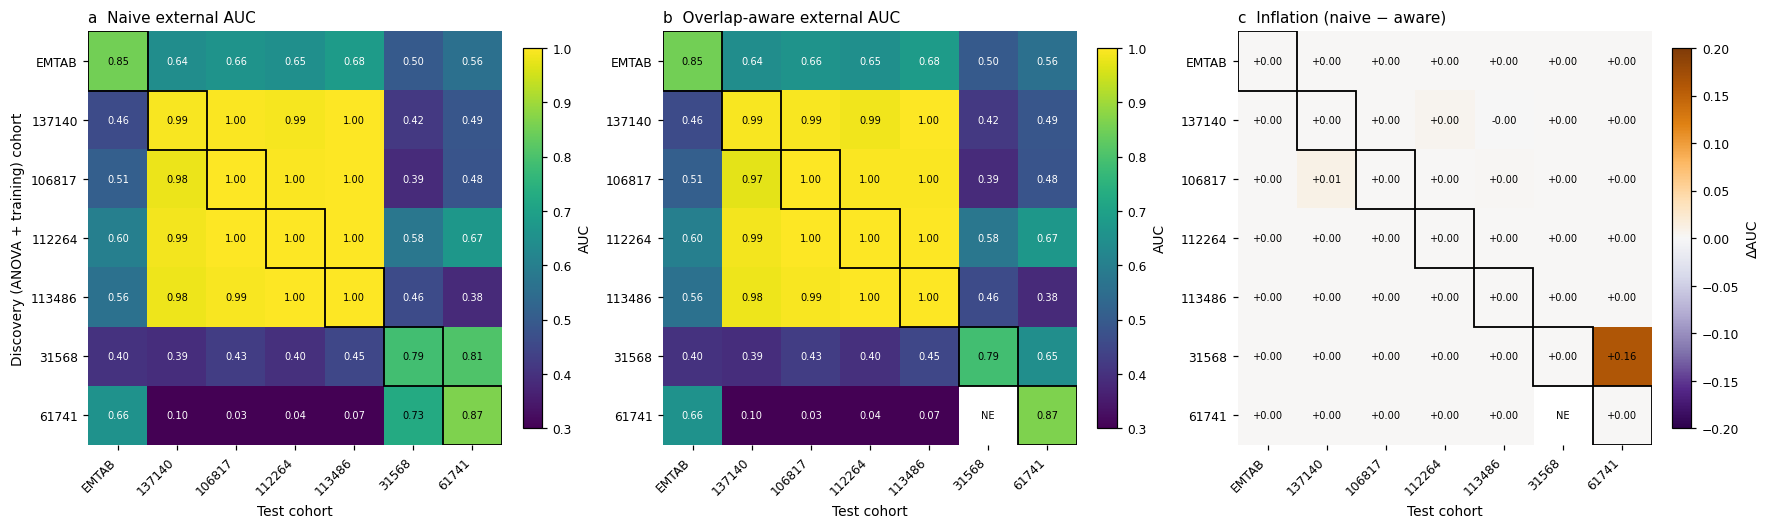

In [14]:
def heat(ax, M, title, vmin=0.3, vmax=1.0, cmap="viridis", fmt="{:.2f}", annot_N=None):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            dark = cmap == "viridis" and np.isfinite(v) and (v - vmin) / (vmax - vmin) < 0.55
            ax.text(j, i, "NE" if not np.isfinite(v) else fmt.format(v), ha="center", va="center", fontsize=6.5,
                    color="white" if dark else "black")
            if i == j:
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec="k", lw=1.2))
    ax.set_xticks(range(7)); ax.set_yticks(range(7))
    ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER], rotation=45, ha="right")
    ax.set_yticklabels([SHORT[c] for c in COHORT_ORDER])
    ax.set_xlabel("Test cohort"); ax.set_ylabel("Discovery (ANOVA + training) cohort")
    ax.set_title(title, loc="left"); ax.spines[:].set_visible(False)
    return im

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
im = heat(axes[0], M_naive, "a  Naive external AUC")
plt.colorbar(im, ax=axes[0], fraction=0.046, label="AUC")
im = heat(axes[1], M_aware, "b  Overlap-aware external AUC")
plt.colorbar(im, ax=axes[1], fraction=0.046, label="AUC")
axes[1].set_ylabel("")
Dl = M_naive - M_aware
im2 = heat(axes[2], Dl, "c  Inflation (naive − aware)", vmin=-0.2, vmax=0.2, cmap="PuOr_r", fmt="{:+.2f}")
plt.colorbar(im2, ax=axes[2], fraction=0.046, label="ΔAUC")
axes[2].set_ylabel("")
savefig(fig, "Fig6_transport_matrix")

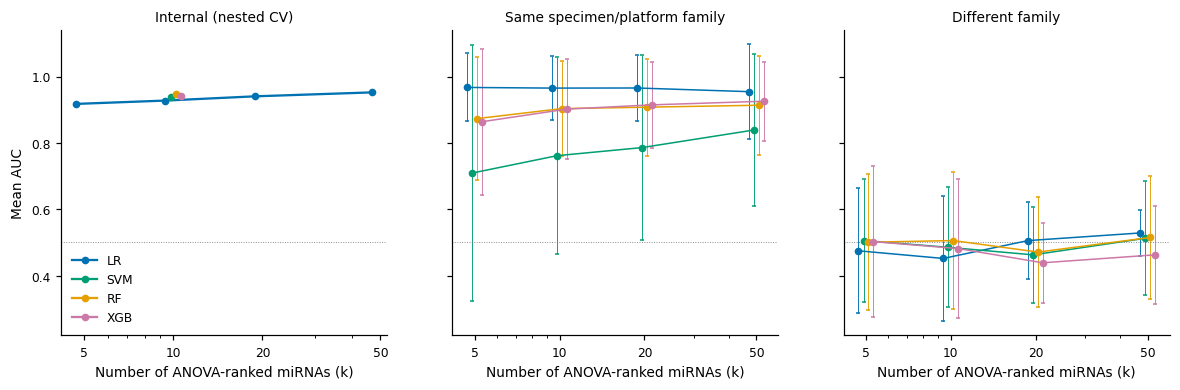

In [15]:
# Aggregate by k and model: within-family vs cross-family transport (overlap-aware)
TRa = TR[TR.setting == "overlap_aware"].copy()
TRa["same_family"] = [COHORTS[a]["family"] == COHORTS[b]["family"] for a, b in zip(TRa.train, TRa.test)]
agg = TRa.groupby(["model", "k", "same_family"]).AUC.agg(["mean", "std", "count"]).reset_index()
agg.to_csv(f"{TAB}/S6_transport_by_model_k_family.csv", index=False)
internal = TR[TR.setting == "internal_nestedCV"].groupby(["model", "k"]).AUC.mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (lab, sub) in zip(axes, [("Internal (nested CV)", None), ("Same specimen/platform family", True),
                                  ("Different family", False)]):
    for jj, (mn, col) in enumerate(zip(MODELS, ["#0072B2", "#009E73", "#E69F00", "#CC79A7"])):
        jit = 1 + 0.04 * (jj - 1.5)
        if sub is None:
            d = internal[internal.model == mn]
            ax.plot(d.k * jit, d.AUC, "o-", ms=4, color=col, label=mn)
        else:
            d = agg[(agg.model == mn) & (agg.same_family == sub)]
            ax.errorbar(d.k * jit, d["mean"], yerr=d["std"], fmt="o-", ms=4, lw=1, elinewidth=0.6, color=col, capsize=1.5, label=mn)
    ax.set_xscale("log"); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID)
    ax.axhline(0.5, c="grey", lw=0.6, ls=":"); ax.set_xlabel("Number of ANOVA-ranked miRNAs (k)")
    ax.set_title(lab, fontsize=9)
axes[0].set_ylabel("Mean AUC"); axes[0].legend(frameon=False)
savefig(fig, "Fig7_k_model_family")
RESULTS["transport_agg"] = agg.round(4).to_dict(orient="records")
RESULTS["internal_agg"] = internal.round(4).to_dict(orient="records")

## 7. Leave-one-cohort-out (LOCO): ANOVA on the pooled, de-duplicated rest → held-out cohort
Two ranking strategies on the pooled rest: (i) pooled ANOVA (cohorts already z-scored within series) and
(ii) random-effects meta-analysis ranking (|z|), which weights consistency across cohorts.

In [16]:
loco_rows = []
loco_scores = {}
for c in COHORT_ORDER:
    rest = [r for r in COHORT_ORDER if r != c]
    masks = dedup_pool(c, rest)
    Xp = pd.concat([data[r][0].loc[masks[r], U] for r in rest]); yp = np.concatenate([data[r][1][masks[r]] for r in rest])
    Xc, yc = data[c][0][U], data[c][1]
    rank_pool = anova_table(Xp, yp).feature.tolist()
    rank_meta = meta_store[c].z.abs().sort_values(ascending=False).index.tolist()
    for strat, rk in [("pooled_ANOVA", rank_pool), ("meta_ANOVA", rank_meta)]:
        for mn in MODELS:
            s, _ = fit_predict(Xp, yp, Xc, mn, rk[:K_MAIN])
            a, lo, hi = auc_delong(yc, s)
            loco_rows.append(dict(HeldOut=c, Strategy=strat, Model=mn, k=K_MAIN, N_train=len(yp), Cases_train=int(yp.sum()),
                                  N_test=len(yc), AUC=a, AUC_lo=lo, AUC_hi=hi,
                                  Signature="; ".join(NAMES.get(f, f).replace("hsa-", "") for f in rk[:K_MAIN])))
            loco_scores[(c, strat, mn)] = s
LOCO = pd.DataFrame(loco_rows); LOCO.to_csv(f"{TAB}/Table7_LOCO.csv", index=False)
RESULTS["loco"] = LOCO.drop(columns="Signature").round(4).to_dict(orient="records")
LOCO.pivot_table(index="HeldOut", columns=["Strategy", "Model"], values="AUC").round(3)

Strategy    meta_ANOVA                      pooled_ANOVA                     
Model               LR     RF    SVM    XGB           LR     RF    SVM    XGB
HeldOut                                                                      
E-MTAB-8026      0.495  0.492  0.509  0.507        0.575  0.575  0.554  0.552
GSE106817        0.633  0.940  0.885  0.933        0.998  0.949  0.870  0.931
GSE112264        0.760  0.987  0.992  0.980        1.000  1.000  1.000  1.000
GSE113486        0.669  0.967  0.978  0.975        1.000  0.990  1.000  1.000
GSE137140        0.592  0.619  0.672  0.754        0.494  0.724  0.816  0.661
GSE31568         0.521  0.530  0.569  0.564        0.567  0.592  0.653  0.588
GSE61741         0.310  0.439  0.397  0.376        0.522  0.547  0.540  0.597

## 8. Sensitivity: removing the sample-level global component (row-centering)

row_centered E-MTAB-8026 done 364 s
row_centered GSE137140 done 370 s
row_centered GSE106817 done 374 s
row_centered GSE112264 done 375 s
row_centered GSE113486 done 376 s
row_centered GSE31568 done 376 s
row_centered GSE61741 done 377 s


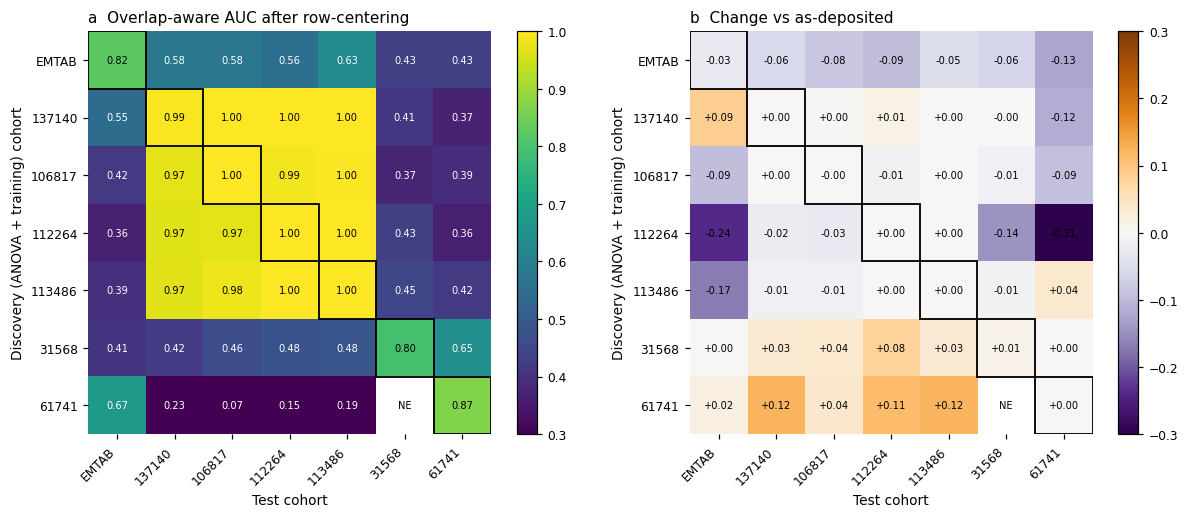

In [17]:
TRc = transport("row_centered", ks=[K_MAIN], models=["LR"])
TRc.to_csv(f"{TAB}/S7_transport_rowcentered.csv", index=False)
M_rc = mat(TRc, "overlap_aware")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
im = heat(axes[0], M_rc, "a  Overlap-aware AUC after row-centering")
plt.colorbar(im, ax=axes[0], fraction=0.046)
im2 = heat(axes[1], M_rc - M_aware, "b  Change vs as-deposited", vmin=-0.3, vmax=0.3, cmap="PuOr_r", fmt="{:+.2f}")
plt.colorbar(im2, ax=axes[1], fraction=0.046)
savefig(fig, "Fig8_rowcentering_sensitivity")
RESULTS["transport_LR_k10_rowcentered"] = M_rc.round(4).to_dict()

## 9. What determines transportability? (overlap-aware, LR, k = 10)

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.5085      0.109      4.673      0.000       0.295       0.722
same_platform    -0.6992      0.410     -1.706      0.088      -1.502       0.104
log_n_train       0.0208      0.041      0.509      0.611      -0.059       0.101
prev_diff        -0.0554      0.110     -0.505      0.614      -0.271       0.160
rho_g             1.3056      0.488      2.675      0.007       0.349       2.262
R2 = 0.798


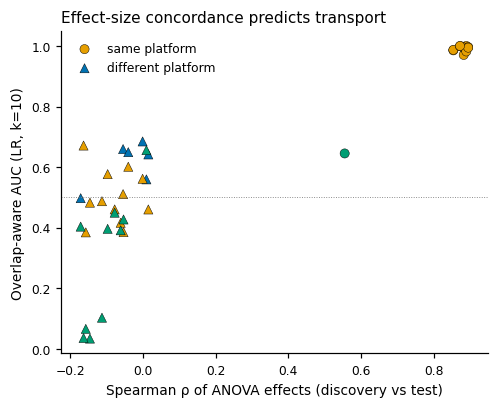

In [18]:
import statsmodels.formula.api as smf
d = TR[(TR.setting == "overlap_aware") & (TR.model == "LR") & (TR.k == K_MAIN)].dropna(subset=["AUC"]).copy()
d["same_specimen"] = [COHORTS[a]["specimen"].split(" ")[0] == COHORTS[b]["specimen"].split(" ")[0] for a, b in zip(d.train, d.test)]
d["same_platform"] = [COHORTS[a]["chemistry"] == COHORTS[b]["chemistry"] for a, b in zip(d.train, d.test)]
d["log_n_train"] = [np.log10(len(data[a][1])) for a in d.train]
d["prev_diff"] = [abs(data[a][1].mean() - data[b][1].mean()) for a, b in zip(d.train, d.test)]
d["rho_g"] = [R.loc[a, b] for a, b in zip(d.train, d.test)]
d["log_cases_test"] = np.log10(d.cases_test)
d = d.astype({"same_specimen": int, "same_platform": int})
ols = smf.ols("AUC ~ same_platform + log_n_train + prev_diff + rho_g", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(d.train)[0]})
T8 = pd.DataFrame({"coef": ols.params, "SE_cluster": ols.bse, "p": ols.pvalues,
                   "CI_lo": ols.conf_int()[0], "CI_hi": ols.conf_int()[1]})
T8.to_csv(f"{TAB}/Table8_determinants_regression.csv")
uni = []
for v in ["same_platform", "same_specimen", "log_n_train", "prev_diff", "rho_g"]:
    r_ = stats.spearmanr(d[v], d.AUC)
    uni.append(dict(variable=v, spearman=r_.correlation, p=r_.pvalue))
pd.DataFrame(uni).to_csv(f"{TAB}/S8_determinants_univariate.csv", index=False)
RESULTS["determinants"] = {"ols": T8.round(4).reset_index().to_dict(orient="records"), "r2": ols.rsquared,
                           "n_pairs": int(len(d)), "univariate": uni}
print(ols.summary().tables[1]); print("R2 =", round(ols.rsquared, 3))

fig, ax = plt.subplots(figsize=(5, 3.8))
for sp, mk in [(1, "o"), (0, "^")]:
    q = d[d.same_platform == sp]
    ax.scatter(q.rho_g, q.AUC, c=[FAMILY_COLORS[COHORTS[t]["family"]] for t in q.train], marker=mk, s=36,
               edgecolor="k", lw=0.3, label="same platform" if sp else "different platform")
ax.set_xlabel("Spearman ρ of ANOVA effects (discovery vs test)"); ax.set_ylabel("Overlap-aware AUC (LR, k=10)")
ax.axhline(0.5, c="grey", lw=0.6, ls=":"); ax.legend(frameon=False)
ax.set_title("Effect-size concordance predicts transport", loc="left")
savefig(fig, "Fig9_determinants")

## 10. Cross-cohort consensus miRNAs (independent core cohorts) and tissue concordance
Independent core cohorts: E-MTAB-8026 (whole blood, Agilent), GSE137140 (serum, 3D-Gene), GSE61741 (whole blood, Geniom)
— no shared participants among them. Criteria: FDR < 0.05 in all three, identical direction, |g| ≥ 0.2 in each.
TCGA LUAD/LUSC tissue (tumour vs adjacent normal) is used as an orthogonal biological reference only.

In [19]:
core = ["E-MTAB-8026", "GSE137140", "GSE61741"]
Xt, yt, ct = load_tcga()
tc = anova_table(Xt, yt).set_index("feature")
cons = pd.DataFrame(index=U)
for c in core + ["GSE106817", "GSE112264", "GSE113486", "GSE31568"]:
    a = anova[c].set_index("feature").loc[U]
    cons[f"g_{SHORT[c]}"] = a.hedges_g; cons[f"FDR_{SHORT[c]}"] = a.FDR
cons["n_sig_core"] = sum((cons[f"FDR_{SHORT[c]}"] < 0.05).astype(int) for c in core)
signs = np.sign(cons[[f"g_{SHORT[c]}" for c in core]])
cons["same_dir_core"] = signs.nunique(axis=1) == 1
cons["min_abs_g_core"] = cons[[f"g_{SHORT[c]}" for c in core]].abs().min(axis=1)
all7 = [f"g_{SHORT[c]}" for c in COHORT_ORDER]
cons["dir_agree_all7"] = (np.sign(cons[all7]).eq(np.sign(cons[f"g_{SHORT['E-MTAB-8026']}"]), axis=0)).mean(axis=1)
cons["g_TCGA_tissue"] = tc.reindex(U).hedges_g.values
cons["FDR_TCGA_tissue"] = tc.reindex(U).FDR.values
meta_all = meta_store  # reuse
sel = cons[(cons.n_sig_core == 3) & cons.same_dir_core & (cons.min_abs_g_core >= 0.2)].copy()
sel["tissue_same_dir"] = np.sign(sel.g_TCGA_tissue) == np.sign(sel[f"g_{SHORT['E-MTAB-8026']}"])
sel.insert(0, "miRNA", [NAMES.get(f, f) for f in sel.index])
sel = sel.sort_values("min_abs_g_core", ascending=False)
sel.to_csv(f"{TAB}/Table9_consensus_miRNAs.csv")
cons.insert(0, "miRNA", [NAMES.get(f, f) for f in cons.index]); cons.to_csv(f"{TAB}/S9_all_common_miRNAs_effects.csv")
RESULTS["consensus"] = {"n": int(len(sel)), "list": sel[["miRNA", "min_abs_g_core", "dir_agree_all7", "g_TCGA_tissue",
                                                            "tissue_same_dir"]].round(3).reset_index().to_dict(orient="records")}
print(len(sel), "consensus miRNAs"); sel.head(20)

74 consensus miRNAs


,miRNA,g_EMTAB,FDR_EMTAB,g_137140,FDR_137140,g_61741,FDR_61741,g_106817,FDR_106817,g_112264,...,FDR_113486,g_31568,FDR_31568,n_sig_core,same_dir_core,min_abs_g_core,dir_agree_all7,g_TCGA_tissue,FDR_TCGA_tissue,tissue_same_dir
MIMAT0005880,hsa-miR-1290,0.658510,7.435431e-33,2.296057,0.000000e+00,0.578381,0.001659,1.773116,4.070603e-72,4.060796,...,9.472738e-19,0.076948,0.887571,3,True,0.578381,1.000000,0.184392,2.142972e-01,True
MIMAT0005911,hsa-miR-1260a,0.464313,2.082985e-17,2.222184,0.000000e+00,0.719265,0.000098,2.306576,1.171624e-116,2.738755,...,8.057637e-13,0.236737,0.622701,3,True,0.464313,1.000000,-0.068043,7.690896e-01,False
MIMAT0005952,hsa-miR-1321,0.452042,1.120912e-16,0.968187,5.181451e-169,0.560550,0.002303,0.972197,8.338459e-24,1.302228,...,1.303109e-03,0.112632,0.848797,3,True,0.452042,1.000000,NaN,1.000000e+00,False
MIMAT0004614,hsa-miR-193a-5p,0.427205,4.485759e-15,1.079939,5.460727e-205,0.604077,0.001030,1.102276,5.897669e-30,1.207319,...,2.878098e-06,0.777585,0.026464,3,True,0.427205,1.000000,-0.876321,3.505052e-14,False
MIMAT0004805,hsa-miR-616-3p,0.422609,8.270137e-15,0.992836,9.498275e-177,0.525998,0.004367,0.949300,8.426198e-23,1.515587,...,6.332506e-09,0.343219,0.397912,3,True,0.422609,1.000000,1.223434,3.730408e-26,True
MIMAT0004792,hsa-miR-92b-5p,0.420622,1.049969e-14,1.632792,0.000000e+00,0.702722,0.000138,1.314935,1.734899e-41,1.668199,...,6.741718e-22,0.372859,0.353451,3,True,0.420622,1.000000,-0.002068,1.000000e+00,False
MIMAT0003218,hsa-miR-92b-3p,0.416488,1.915481e-14,2.115222,0.000000e+00,0.414090,0.025727,2.867824,1.416255e-171,2.878857,...,2.785613e-24,0.025452,0.961590,3,True,0.414090,1.000000,0.164056,2.844938e-01,True
MIMAT0004767,hsa-miR-193b-5p,0.416150,1.989589e-14,0.412493,7.496285e-35,0.420346,0.024113,0.247294,1.019673e-02,0.645366,...,6.314651e-01,0.183512,0.714521,3,True,0.412493,1.000000,1.003406,3.683934e-18,True
MIMAT0003326,hsa-miR-663a,0.423107,7.929643e-15,3.222272,0.000000e+00,0.411412,0.026759,3.649897,7.271133e-258,4.036150,...,2.905591e-48,0.000728,0.998973,3,True,0.411412,1.000000,0.057210,8.311834e-01,True
MIMAT0005944,hsa-miR-1252-5p,0.406654,7.372646e-14,1.119582,2.796293e-218,0.535697,0.003705,1.259413,2.713453e-38,1.544163,...,1.472081e-09,0.067078,0.896183,3,True,0.406654,1.000000,0.099458,6.003759e-01,True


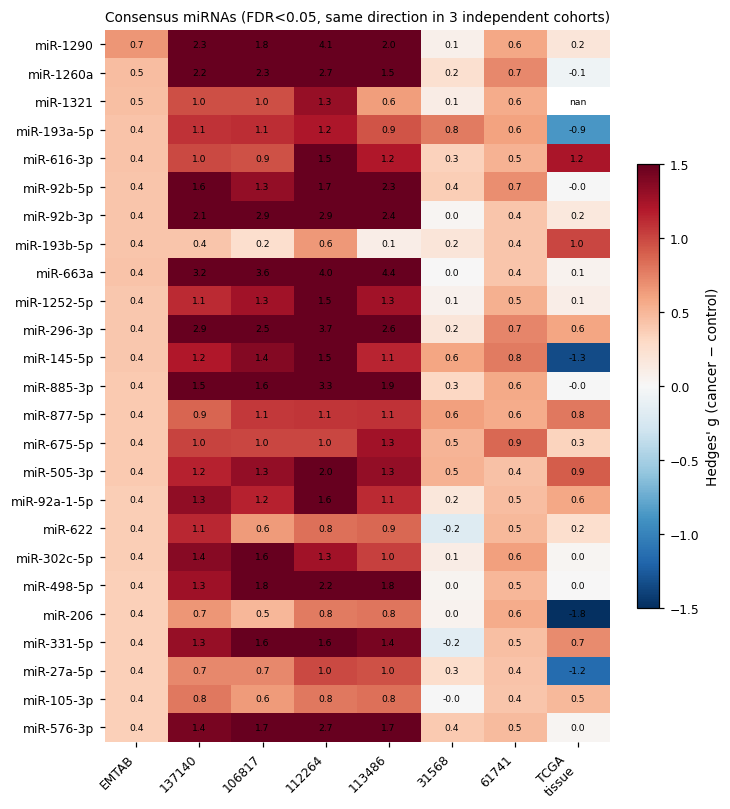

In [20]:
if len(sel):
    show = sel.head(25)
    H = show[[f"g_{SHORT[c]}" for c in COHORT_ORDER] + ["g_TCGA_tissue"]]
    fig, ax = plt.subplots(figsize=(6.5, 0.28 * len(show) + 1.4))
    im = ax.imshow(H.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
    ax.set_yticks(range(len(show))); ax.set_yticklabels([m.replace("hsa-", "") for m in show.miRNA])
    ax.set_xticks(range(H.shape[1])); ax.set_xticklabels([SHORT[c] for c in COHORT_ORDER] + ["TCGA\ntissue"], rotation=45, ha="right")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            ax.text(j, i, f"{H.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
    plt.colorbar(im, ax=ax, fraction=0.04, label="Hedges' g (cancer − control)")
    ax.set_title("Consensus miRNAs (FDR<0.05, same direction in 3 independent cohorts)", loc="left", fontsize=9)
    ax.spines[:].set_visible(False)
    savefig(fig, "Fig10_consensus_heatmap")

## 11. Leave-one-core-cohort-out consensus (does cross-cohort agreement buy transportability?)
The consensus list above uses all three core cohorts, so evaluating it on them would be circular, and the remaining
series share participants with GSE137140 or GSE61741. We therefore re-derive the consensus from two core cohorts
(FDR < 0.05 and same direction in both; ranked by the smaller |g|), train LR on those two pooled cohorts, and test on the
third, fully independent core cohort. The comparator is a pooled-ANOVA top-10 signature from the same two cohorts.

In [21]:
cs_rows = []
for h in core:
    tr_c = [c for c in core if c != h]
    a1 = anova[tr_c[0]].set_index("feature").loc[U]; a2 = anova[tr_c[1]].set_index("feature").loc[U]
    ok = (a1.FDR < 0.05) & (a2.FDR < 0.05) & (np.sign(a1.hedges_g) == np.sign(a2.hedges_g))
    score = np.minimum(a1.hedges_g.abs(), a2.hedges_g.abs()).where(ok, -1)
    cfe = score.sort_values(ascending=False).index[:K_MAIN].tolist()
    Xp = pd.concat([data[c][0][U] for c in tr_c]); yp = np.concatenate([data[c][1] for c in tr_c])
    pfe = anova_table(Xp, yp).feature[:K_MAIN].tolist()
    yh = data[h][1]
    s1, _ = fit_predict(Xp, yp, data[h][0][U], "LR", cfe)
    s2, _ = fit_predict(Xp, yp, data[h][0][U], "LR", pfe)
    a_, lo, hi = auc_delong(yh, s1); b_, blo, bhi = auc_delong(yh, s2)
    _, _, pdl = delong_paired(yh, s1, s2)
    cs_rows.append(dict(HeldOut=h, Derivation=" + ".join(tr_c), n_consensus_candidates=int(ok.sum()),
                        AUC_consensus=a_, lo=lo, hi=hi, AUC_pooledANOVA=b_, lo_p=blo, hi_p=bhi, DeLong_p=pdl,
                        Consensus_signature="; ".join(NAMES.get(f, f).replace("hsa-", "") for f in cfe)))
CS = pd.DataFrame(cs_rows); CS.to_csv(f"{TAB}/Table10_leave_one_core_out_consensus.csv", index=False)
RESULTS["consensus_loco"] = CS.round(4).to_dict(orient="records")
CS

,HeldOut,Derivation,n_consensus_candidates,AUC_consensus,lo,hi,AUC_pooledANOVA,lo_p,hi_p,DeLong_p,Consensus_signature
0,E-MTAB-8026,GSE137140 + GSE61741,138,0.536591,0.507129,0.566053,0.543981,0.513970,0.573992,0.666393,miR-19b-3p; miR-130b-5p; miR-93-3p; miR-484; m...
1,GSE137140,E-MTAB-8026 + GSE61741,143,0.256292,0.240662,0.271921,0.600732,0.582709,0.618755,0.000000,miR-126-3p; miR-374b-5p; miR-1290; miR-197-3p;...
2,GSE61741,E-MTAB-8026 + GSE137140,568,0.651559,0.564630,0.738489,0.770329,0.700163,0.840496,0.000705,miR-940; miR-33b-3p; miR-1290; miR-23a-5p; miR...


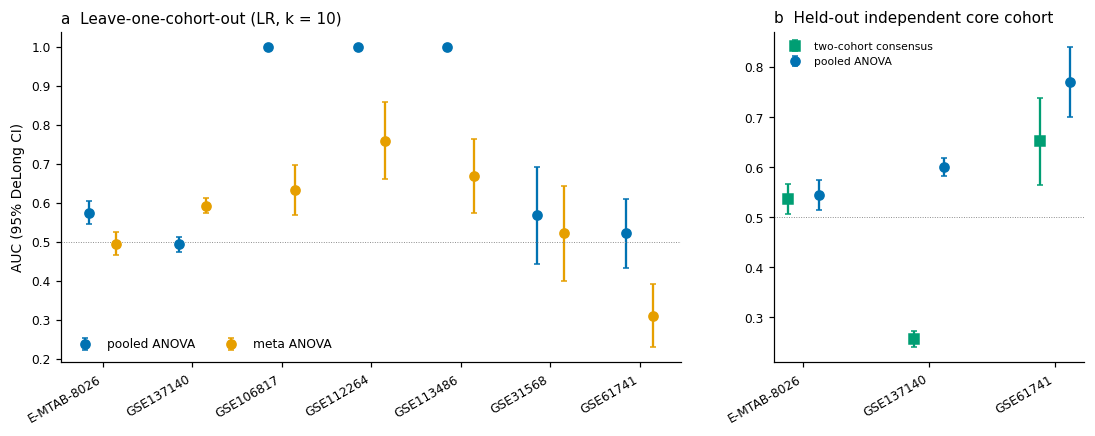

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw=dict(width_ratios=[2, 1]))
ax = axes[0]
lo_ = LOCO[(LOCO.Model == "LR")]
xx = np.arange(7)
for off, (strat, col) in zip([-0.15, 0.15], [("pooled_ANOVA", "#0072B2"), ("meta_ANOVA", "#E69F00")]):
    q = lo_[lo_.Strategy == strat].set_index("HeldOut").reindex(COHORT_ORDER)
    v, lo, hi = q.AUC, q.AUC_lo, q.AUC_hi
    ax.errorbar(xx + off, v, yerr=[v - lo, hi - v], fmt="o", color=col, capsize=2, label=strat.replace("_", " "))
ax.axhline(0.5, c="grey", lw=0.6, ls=":")
ax.set_xticks(xx); ax.set_xticklabels(COHORT_ORDER, rotation=30, ha="right")
ax.set_ylabel("AUC (95% DeLong CI)"); ax.set_title("a  Leave-one-cohort-out (LR, k = 10)", loc="left")
ax.legend(frameon=False, ncol=2)
ax = axes[1]
xx = np.arange(len(CS))
ax.errorbar(xx - 0.12, CS.AUC_consensus, yerr=[CS.AUC_consensus - CS.lo, CS.hi - CS.AUC_consensus], fmt="s", c="#009E73", capsize=2, label="two-cohort consensus")
ax.errorbar(xx + 0.12, CS.AUC_pooledANOVA, yerr=[CS.AUC_pooledANOVA - CS.lo_p, CS.hi_p - CS.AUC_pooledANOVA], fmt="o", c="#0072B2", capsize=2, label="pooled ANOVA")
ax.axhline(0.5, c="grey", lw=0.6, ls=":")
ax.set_xticks(xx); ax.set_xticklabels(CS.HeldOut, rotation=30, ha="right")
ax.set_title("b  Held-out independent core cohort", loc="left"); ax.legend(frameon=False, fontsize=7)
savefig(fig, "Fig11_LOCO_consensus")

In [23]:
with pd.ExcelWriter(f"{TAB}/PaperLu1_all_tables.xlsx") as xw:
    for f in sorted(os.listdir(TAB)):
        if f.endswith(".csv"):
            pd.read_csv(f"{TAB}/{f}").to_excel(xw, sheet_name=f[:31].replace(".csv", ""), index=False)
RESULTS["universe_size"] = len(U)
RESULTS["runtime_min"] = round((time.time() - t0) / 60, 1)
json.dump(RESULTS, open("results_summary.json", "w"), indent=1, default=float)
print("Finished in", RESULTS["runtime_min"], "min")

Finished in 6.8 min
